# 11 · AI Cricket Coach

A coach that answers questions and recommends practice from stored statistics. It works offline with rules, and can use a language model to phrase the answer.

Needs: numpy, pandas, matplotlib (anthropic is optional) (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. How it works

1. Ingest: build a table of statistics for each player from the matches, sessions and readings.
2. Retrieve: pick the figures that bear on the question.
3. Answer: write the answer from those figures, with the evidence listed.
4. Optionally rephrase the answer with a language model that is given only the retrieved figures.

The rule-based path is the default. It needs no key and no internet, and every number in its answer can be traced to a row of data.

In [2]:
from pitchvision import coach, scoring, stats, pitchmap

balls = pd.read_csv(DATA / "balls.csv"); players = pd.read_csv(DATA / "players.csv")
speeds = pd.read_csv(DATA / "speeds.csv"); deliveries = pd.read_csv(DATA / "deliveries.csv"); fielding = pd.read_csv(DATA / "fielding.csv")
ours = set(players["name"])

lines = scoring.lines_from_balls(balls.to_dict("records"))
batting = [r for r in stats.career_batting([l for l in lines["batting"] if l["player"] in ours])]
bowling = [r for r in stats.career_bowling([l for l in lines["bowling"] if l["player"] in ours])]
for r in batting + bowling: r["name"] = r["player"]
fielding_rows = stats.career_fielding(fielding.to_dict("records"))

accuracy = {}
for name, g in deliveries.dropna(subset=["x", "y"]).groupby("player"):
    ty = 5.2 if g["bowl_type"].iloc[0] == "spin" else 7.0
    accuracy[name] = pitchmap.accuracy(g.to_dict("records"), 0.2, ty)
speed_history = {n: g.sort_values("date").dropna(subset=["kmh"])[["date", "kmh", "source"]].to_dict("records") for n, g in speeds.groupby("player")}
splits = {n: stats.batting_splits(balls.to_dict("records"), n) for n in ours}

ctx = {"players": [{"id": r["name"], "name": r["name"], "role": r["role"], "bowl_style": r["bowl_style"]} for _, r in players.iterrows()],
       "batting": batting, "bowling": bowling, "fielding": fielding_rows, "speeds": speed_history, "accuracy": accuracy, "splits": splits, "me": "Imran Khan"}
print("Statistics loaded for", len(ctx["players"]), "players (SYNTHETIC). 'me' is set to Imran Khan.")

Statistics loaded for 14 players (SYNTHETIC). 'me' is set to Imran Khan.


## 2. Summaries

In [3]:
eco = pd.DataFrame(bowling).set_index("name")[["overs", "wickets", "economy", "average"]].round(2).sort_values("economy")
print("Team economy:", round(sum(b["runs"] for b in bowling) * 6 / sum(b["legal_balls"] for b in bowling), 2))
eco.head(6)

Team economy: 5.95


,overs,wickets,economy,average
name,,,,
George Hill,16.4,7,5.10,12.14
Liam Shaw,21.0,8,5.14,13.50
Milan Das,19.0,7,5.37,14.57
Kabir Rao,19.0,8,5.47,13.00
Jack Wood,17.5,5,6.22,22.20
Farhan Ali,21.0,7,6.57,19.71


## 3. Questions and answers

Each answer states the data behind it. When the data is too thin the answer says so and names what to record.

In [4]:
for q in coach.SUGGESTED_QUESTIONS:
    r = coach.answer(q, ctx)
    print("Q:", q); print("A:", r["answer"])
    for e in r["evidence"][:3]: print("    ", e)
    print()

Q: What should I improve as a bowler?
A: Priorities for you: (1) Bowling accuracy: Targeted line-and-length practice. (2) Bowling economy: You concede more per over than the team rate; work on a stock ball you can land under pressure.
     Bowling accuracy: 35% of 96 recorded deliveries landed in the target zone (below 40%). Drill: Place a mat or two cones on a good length outside off stump. Bowl sets of 12 and count hits; aim to beat your previous set.
     Bowling economy: Economy 7.29 against a team economy of 5.95 (14.0 overs bowled). Drill: Target bowling with a batter: 12 balls where anything outside the target zone counts as 4 runs.

Q: Which of our bowlers has the best economy?
A: George Hill has the best economy rate: 5.10 runs per over (16.4 overs). Ranked among players with at least 30 balls bowled.
     1. George Hill: 5.10 runs per over (16.4 overs)
     2. Liam Shaw: 5.14 runs per over (21.0 overs)
     3. Milan Das: 5.37 runs per over (19.0 overs)

Q: Who performs best a

In [5]:
# Check one answer against the table by hand: the best economy among bowlers with at least 30 balls.
best = min((b for b in bowling if b["legal_balls"] >= 30), key=lambda b: b["economy"])
reply = coach.answer("Which of our bowlers has the best economy?", ctx)
assert best["name"] in reply["answer"] and f"{best['economy']:.2f}" in reply["answer"]
print("Verified against the table:", best["name"], round(best["economy"], 2))

# With no data the coach says so and invents nothing.
empty = {"players": [{"id": 1, "name": "Sam Lee", "role": "bowler"}], "me": 1}
for q in ["Which of our bowlers has the best economy?", "Who is our fastest bowler?", "What should I improve as a bowler?"]:
    print(q, "->", coach.answer(q, empty)["answer"])

Verified against the table: George Hill 5.1
Which of our bowlers has the best economy? -> There is not enough recorded data to answer that yet (at least 30 balls bowled).
Who is our fastest bowler? -> No bowling speeds have been recorded yet.
What should I improve as a bowler? -> Nothing in the recorded data for you crosses a coaching threshold yet. Either there is too little data, or the numbers are within the normal range. Record more sessions and matches.


## 4. Recommendations with their evidence

A recommendation fires when a recorded figure crosses a stated threshold. The figure and the threshold go in the output.

In [6]:
rows = []
for p in ctx["players"]:
    for rec in coach.player_recommendations(ctx, p["id"]):
        rows.append({"player": p["name"], "area": rec["area"], "recommendation": rec["recommendation"], "evidence": rec["evidence"], "drill": rec["drill"]})
recs = pd.DataFrame(rows)
print(len(recs), "recommendations for", recs["player"].nunique(), "players")
pd.set_option("display.max_colwidth", 140); recs.head(8)

48 recommendations for 12 players


,player,area,recommendation,evidence,drill
0,Ben Carter,Batting against pace,You score much more slowly against pace than spin.,Strike rate 91 vs pace (33 balls) and 144 vs spin (18 balls).,Bowling-machine or side-arm work at match pace; back-foot punch and leave drills.
1,Ben Carter,Dismissals against pace,You are getting out often against pace.,5 dismissals for 30 runs against pace (average 6.0).,Net sessions against pace with a 'survive 30 balls' target before playing shots.
2,Dev Patel,Dismissals against pace,You are getting out often against pace.,5 dismissals for 46 runs against pace (average 9.2).,Net sessions against pace with a 'survive 30 balls' target before playing shots.
3,Dev Patel,Starting an innings,You are often out before reaching 10.,Out for under 10 in 5 of 8 innings.,"First-20-balls routine in the nets: leave, defend, and only score in your strongest area."
4,Ethan Brooks,Bowling accuracy,Targeted line-and-length practice.,16% of 96 recorded deliveries landed in the target zone (below 40%).,Place a mat or two cones on a good length outside off stump. Bowl sets of 12 and count hits; aim to beat your previous set.
5,Ethan Brooks,Bowling line,Tighten your line: the sideways spread of your deliveries is wide.,Lateral spread 31 cm (standard deviation) over 96 deliveries (above 30 cm).,Bowl to a single stump with a channel marked 20 cm either side; focus on a repeatable wrist and front-arm position.
6,Ethan Brooks,Dismissals against pace,You are getting out often against pace.,5 dismissals for 46 runs against pace (average 9.2).,Net sessions against pace with a 'survive 30 balls' target before playing shots.
7,Ethan Brooks,Catching,Catching practice: your catch success rate is low.,"1 caught and 3 dropped (25% of 4 chances, below 60%).",20 catches a session split between high balls and flat catches; add reaction catches off a ramp or wall.


In [7]:
print("Team-level insights")
for i in coach.team_insights(ctx):
    print(f"- {i['title']}: {i['detail']} ({i['evidence']})")
recs.to_csv(EXPORTS / "coaching_recommendations.csv", index=False)
print("\nThresholds used:")
for name, value in [("balls in a pace/spin split", coach.MIN_BALLS_SPLIT), ("balls bowled before economy is read", coach.MIN_BALLS_BOWLED), ("catching chances before a catch % is read", coach.MIN_CHANCES)]:
    print(f" - {name}: {value}")

Team-level insights
- Team economy rate: 5.95 runs per over. (854 runs from 143.3 overs.)
- Runs per wicket (batting): 11.1. (786 runs for 71 dismissals.)
- Catching: The team holds 60% of its catches. (39 caught, 26 dropped.)

Thresholds used:
 - balls in a pace/spin split: 12
 - balls bowled before economy is read: 30
 - catching chances before a catch % is read: 3


## 5. Optional: phrasing with a language model

If an `ANTHROPIC_API_KEY` is set, the retrieved facts can be handed to Claude, which is told to use only those facts. Nothing else about the notebook changes. Without a key this cell prints the rule-based answer and carries on.

In [8]:
import os
print("Language model available:", coach.llm_available())
question = "What should I improve as a bowler?"
reply = coach.answer(question, ctx, use_llm=True)
print("Engine used:", reply["engine"])
print(reply["answer"])
if reply.get("llm_note"): print("Note:", reply["llm_note"])
# To switch it on:   os.environ["ANTHROPIC_API_KEY"] = "..."   (keep keys out of notebooks you share)

Language model available: False
Engine used: rules
Priorities for you: (1) Bowling accuracy: Targeted line-and-length practice. (2) Bowling economy: You concede more per over than the team rate; work on a stock ball you can land under pressure.
Note: No ANTHROPIC_API_KEY is set; using the built-in rule-based coach.


## 6. Plotting the evidence

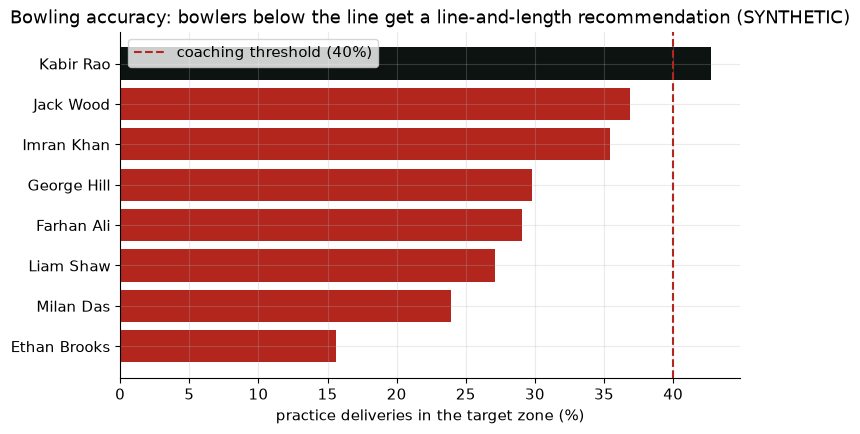

In [9]:
acc = pd.DataFrame(accuracy).T[["hit_pct", "total"]].sort_values("hit_pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(acc.index, acc["hit_pct"], color=[RED if v < 40 else INK for v in acc["hit_pct"]])
ax.axvline(40, color=RED, ls="--", label="coaching threshold (40%)"); ax.legend()
ax.set_xlabel("practice deliveries in the target zone (%)"); ax.set_title("Bowling accuracy: bowlers below the line get a line-and-length recommendation (SYNTHETIC)"); plt.show()

## Summary

### Key findings
- The coach answers each question from the table of statistics and prints the rows it used.
- With no data it says so, and the recommendation list stays empty.
- Each recommendation carries its trigger figure, and the thresholds are constants anyone can read and change.

### Interpretation
A rule-based coach is easy to check: if an answer looks wrong, the evidence lines show why. A language model makes the prose smoother but adds nothing the rules did not already find.

### Limitations
- The rules cover a short list of questions. Anything else gets a polite 'I can answer questions about...'.
- Thresholds such as 40% in the target zone are coaching rules of thumb, not measured standards.
- With synthetic data the recommendations show the mechanism, not real weaknesses.
- A language model can still misread the facts it is given. Treat its wording as a draft and check the evidence list.

### How this notebook connects to the application
The AI Coach page calls `POST /api/coach/ask` and `GET /api/coach/recommendations`, which build the same context from the database and call `coach.answer` and `coach.player_recommendations`. The language-model checkbox calls the same `coach.llm_answer` used above.